# PA-S1. Начало работы: продуктовая аналитика H&M

Дисциплина «Продуктовая аналитика», трек Б (индивидуальный)

Автор: Шабрин Алексей, ИУ5-55Б, МГТУ им. Баумана

Репозиторий: https://github.com/Alexis1534/hm-product-analytics

## Датасет

Взяты данные H&M Group из соревнования Kaggle «H&M Personalized Fashion Recommendations» (2022). Это реальные покупки одежды с 20.09.2018 по 22.09.2020: 31,8 млн строк. К ним есть справочник покупателей (1,37 млн) и справочник товаров (105,5 тыс.). ID покупателей и почтовые индексы заменены хешами, цены нормированы, так что никаких рублей или евро тут нет. Событие в данных одно, покупка, и у неё есть дата, но нет времени.

Файлы скачаны с Kaggle через официальный API после принятия правил соревнования.

Как запустить: склонировать репозиторий, поставить зависимости из `requirements.txt` и выполнить ноутбук сверху вниз. Если в `data/` нет файлов, первая ячейка скачает их сама, для этого нужен токен Kaggle в переменной `KAGGLE_API_TOKEN`. Пути везде относительные. Первый запуск вместе со скачиванием занимает около 10 минут, потом данные лежат в базе `data/hm.duckdb`, и повторные запуски быстрее.

## 0. Настройка

Параметры определений (окна по 90 дней, границы когорт и т. п.) собраны в одной ячейке и дальше по ноутбуку не меняются.

In [2]:
import sys, subprocess, platform
from pathlib import Path

import numpy as np
import pandas as pd
import duckdb
import matplotlib
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
# целые печатаем без дробной части, остальное с 4 знаками
pd.set_option("display.float_format", lambda x: f"{x:,.0f}" if float(x).is_integer() else f"{x:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

DATA_DIR = Path("data")      # csv с kaggle, в git не идут
OUT_DIR = Path("outputs")    # таблицы, которые считаются здесь
OUT_DIR.mkdir(exist_ok=True)

FILES = {"transactions": "transactions_train.csv",
         "customers": "customers.csv",
         "articles": "articles.csv"}

# параметры определений (раздел 3)
PRICE_SCALE = 1000            # цена нормирована, 1 у.е. = price * 1000
RETURN_LOOKBACK_DAYS = 365    # повторный покупатель: покупал за 365 дней до начала месяца
CONVERSION_DAYS = 90          # конверсия: второй заказ за 90 дней
CHURN_DAYS = 90               # отток: 90 дней без покупок
COHORT_START = "2019-09-01"   # когорты сен 2019 - фев 2020
COHORT_END = "2020-03-01"
MAX_K = 6                     # смотрим месяцы 0..6
TEST_ITEMS_PER_DAY = 100      # 100+ вещей за день - не розничный покупатель
SEED = 42

missing = [f for f in FILES.values() if not (DATA_DIR / f).exists()]
if missing:
    print("Нет файлов:", missing, "- скачиваю через Kaggle API")
    subprocess.run([sys.executable, "scripts/download_data.py"], check=True)

print("Python", platform.python_version(), "| duckdb", duckdb.__version__, "| pandas", pd.__version__,
      "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)
for f in FILES.values():
    print(f"{f:<24} {(DATA_DIR / f).stat().st_size / 1e6:>9,.1f} MB")

Нет файлов: ['transactions_train.csv', 'customers.csv', 'articles.csv'] - скачиваю через Kaggle API
Python 3.13.16 | duckdb 1.4.1 | pandas 2.2.3 | numpy 2.1.3 | matplotlib 3.10.0
transactions_train.csv     3,488.0 MB
customers.csv                207.1 MB
articles.csv                  36.1 MB


In [3]:
# csv один раз грузим в duckdb, дальше всё считаем по базе
# article_id читаем строкой, иначе пропадёт ведущий ноль
con = duckdb.connect(str(DATA_DIR / "hm.duckdb"))
con.execute("SET preserve_insertion_order = false")
con.execute("SET enable_progress_bar = false")
existing = set(con.sql("SELECT table_name FROM information_schema.tables").df()["table_name"])

def csv(name):
    return (DATA_DIR / FILES[name]).as_posix()

if "tx" not in existing:
    con.execute(f"""
        CREATE TABLE tx AS
        SELECT t_dat, customer_id, lpad(article_id, 10, '0') AS article_id, price, sales_channel_id
        FROM read_csv('{csv("transactions")}', header = true,
             columns = {{'t_dat': 'DATE', 'customer_id': 'VARCHAR', 'article_id': 'VARCHAR',
                         'price': 'DOUBLE', 'sales_channel_id': 'INTEGER'}})""")
if "customers" not in existing:
    con.execute(f"""
        CREATE TABLE customers AS
        SELECT * FROM read_csv('{csv("customers")}', header = true,
             types = {{'customer_id': 'VARCHAR', 'age': 'DOUBLE', 'postal_code': 'VARCHAR',
                       'club_member_status': 'VARCHAR', 'fashion_news_frequency': 'VARCHAR'}})""")
if "articles" not in existing:
    con.execute(f"""
        CREATE TABLE articles AS
        SELECT * REPLACE (lpad(article_id, 10, '0') AS article_id)
        FROM read_csv('{csv("articles")}', header = true,
             types = {{'article_id': 'VARCHAR', 'product_code': 'VARCHAR'}})""")

for t in ["tx", "customers", "articles"]:
    n = con.sql(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
    print(f"{t:<10} {n:>12,} строк")

tx           31,788,324 строк
customers     1,371,980 строк
articles        105,542 строк


## 1. Продукт

H&M это сеть магазинов одежды, которая продаёт и в обычных магазинах, и через интернет-магазин. По описанию соревнования у компании 53 онлайн-рынка и около 4 850 магазинов, в справочнике 105 542 артикула.

Аудитория массовая. Медианный возраст покупателя в `customers.csv` 32 года, половина покупателей от 24 до 49 лет (гистограмма в 2.3), 93 % состоят в клубе H&M.

Проблема, на которую я смотрю: ассортимент огромный, найти в нём подходящее трудно, и многие покупают один раз и больше не возвращаются. В данных это видно: в следующем месяце после первой покупки снова покупают только 12–16 % новых клиентов (6.1).

Гипотеза: если после первой покупки показывать персональные рекомендации, человек быстрее найдёт следующую вещь, и больше новых покупателей сделают второй заказ в течение 90 дней. Тогда вырастут число повторных покупателей (North Star) и LTV, а тратить больше на привлечение не придётся.

H&M зарабатывает продажей товаров, валовая маржа группы за 2019 финансовый год 52,6 % (годовой отчёт). Покупателей приводит маркетинг, покупают они через два канала продаж. Поэтому главный вопрос юнит-экономики такой: окупается ли покупатель валовой прибылью за первые месяцы (LTV/CAC).

## 2. Данные

| Параметр | Значение |
|---|---|
| Источник | Kaggle, соревнование H&M Personalized Fashion Recommendations, данные выложила H&M Group |
| Файлы | `transactions_train.csv` (3,5 ГБ), `customers.csv` (207 МБ), `articles.csv` (36 МБ); картинки товаров не нужны |
| Лицензия | правила соревнования на Kaggle (вкладка Rules). Данные нельзя распространять вне Kaggle, поэтому в репозитории их нет, их скачивает `scripts/download_data.py` |
| Версия | версий у данных соревнования нет (оно шло в начале 2022 года). Для контроля ниже выводятся число строк и диапазон дат |
| Период | 20.09.2018 – 22.09.2020, 734 дня без пропусков |
| Объём | 31,8 млн строк покупок, 1,36 млн покупателей с покупками, 104,5 тыс. артикулов в покупках (105,5 тыс. в справочнике) |
| События | только покупка: одна строка = одна купленная вещь, дата без времени |

В `transactions_train` дата, покупатель, артикул, цена и канал продаж (1 или 2, что это значит, в описании не сказано). В `customers` возраст, статус в клубе, подписка на рассылку и хеш почтового индекса. В `articles` иерархия товара (21 группа одежды, 19 групп продуктов), цвет и текстовое описание.

In [4]:
ov = con.sql('''
    SELECT COUNT(*) AS rows, COUNT(DISTINCT customer_id) AS customers, COUNT(DISTINCT article_id) AS articles,
           MIN(t_dat) AS date_min, MAX(t_dat) AS date_max, COUNT(DISTINCT t_dat) AS days_with_data,
           date_diff('day', MIN(t_dat), MAX(t_dat)) + 1 AS days_in_range,
           AVG(CASE WHEN sales_channel_id = 2 THEN 1.0 ELSE 0 END) AS share_channel_2,
           MIN(price) AS price_min, quantile_cont(price, 0.5) AS price_p50,
           quantile_cont(price, 0.99) AS price_p99, MAX(price) AS price_max
    FROM tx''').df().T
ov.columns = ["значение"]
print(ov.to_string())
MAX_DATE = pd.Timestamp(con.sql("SELECT MAX(t_dat) FROM tx").fetchone()[0])
MIN_DATE = pd.Timestamp(con.sql("SELECT MIN(t_dat) FROM tx").fetchone()[0])

                            значение
rows                        31788324
customers                    1362281
articles                      104547
date_min         2018-09-20 00:00:00
date_max         2020-09-22 00:00:00
days_with_data                   734
days_in_range                    734
share_channel_2               0.7040
price_min                     0.0000
price_p50                     0.0254
price_p99                     0.1002
price_max                     0.5915


### 2.1 Пропуски

Доля пустых значений по каждому столбцу трёх таблиц. В ключевых полях покупок (дата, покупатель, артикул, цена, канал) пропусков быть не должно.

Большие доли у `FN` и `Active` в `customers` не ошибка: в этих флагах стоит либо 1, либо пусто, и пусто значит «нет».

In [5]:
def null_shares(table):
    cols = con.sql(f"DESCRIBE {table}").df()["column_name"].tolist()
    expr = ", ".join(f'AVG(CASE WHEN "{c}" IS NULL THEN 1.0 ELSE 0 END) AS "{c}"' for c in cols)
    s = con.sql(f"SELECT {expr} FROM {table}").df().T[0]
    return s[s > 0].sort_values(ascending=False)

for t in ["tx", "customers", "articles"]:
    s = null_shares(t)
    print(f"\n{t}: столбцов с пропусками {len(s)}")
    if len(s):
        print((s * 100).round(2).astype(str).add(" %").to_string())


tx: столбцов с пропусками 0

customers: столбцов с пропусками 5
Active                    66.15 %
FN                        65.24 %
fashion_news_frequency     1.17 %
age                        1.16 %
club_member_status         0.44 %

articles: столбцов с пропусками 1
detail_desc    0.39 %


### 2.2 Дубли

Номера чека и количества в данных нет, поэтому две одинаковые футболки, купленные в один день, дают две одинаковые строки. Полностью совпадающие строки (их 9,4 %) я считаю покупкой нескольких штук и не удаляю, иначе занижу выручку. Заодно проверяю повторы ключей в справочниках и ссылки из покупок на несуществующих покупателей и артикулы.

In [6]:
dup = con.sql('''
    SELECT (SELECT COUNT(*) FROM tx) AS rows,
           (SELECT COUNT(*) FROM (SELECT DISTINCT * FROM tx)) AS distinct_rows,
           (SELECT COUNT(*) - COUNT(DISTINCT customer_id) FROM customers) AS dup_customer_id,
           (SELECT COUNT(*) - COUNT(DISTINCT article_id) FROM articles) AS dup_article_id,
           (SELECT COUNT(*) FROM (SELECT DISTINCT customer_id FROM tx)
             WHERE customer_id NOT IN (SELECT customer_id FROM customers)) AS tx_customers_not_in_table,
           (SELECT COUNT(*) FROM tx WHERE article_id NOT IN (SELECT article_id FROM articles)) AS tx_rows_unknown_article
''').df().T[0]
dup["repeated_rows"] = dup["rows"] - dup["distinct_rows"]
dup["repeated_share_%"] = dup["repeated_rows"] / dup["rows"] * 100
print(dup.to_string())

rows                        31,788,324
distinct_rows               28,813,419
dup_customer_id                      0
dup_article_id                       0
tx_customers_not_in_table            0
tx_rows_unknown_article              0
repeated_rows                2,974,905
repeated_share_%                9.3585


### 2.3 Согласованность значений

Смотрю разные написания одного значения, заглушку в почтовом индексе, возраст вне разумного диапазона и неизвестные типы товара.

In [7]:
print(con.sql('''SELECT COALESCE(fashion_news_frequency, '<пусто>') AS fashion_news_frequency, COUNT(*) AS n FROM customers GROUP BY 1 ORDER BY 2 DESC''').df().to_string(index=False))
print()
print(con.sql('''SELECT COALESCE(club_member_status, '<пусто>') AS club_member_status, COUNT(*) AS n FROM customers GROUP BY 1 ORDER BY 2 DESC''').df().to_string(index=False))
print()
top_postal = con.sql('''SELECT postal_code, COUNT(*) AS n FROM customers GROUP BY 1 ORDER BY 2 DESC LIMIT 3''').df()
top_postal["postal_code"] = top_postal["postal_code"].str[:12] + "..."
print(top_postal.to_string(index=False))
print()
print(con.sql('''
    SELECT MIN(age) AS age_min, MAX(age) AS age_max,
           AVG(CASE WHEN age < 16 OR age > 99 THEN 1.0 ELSE 0 END) AS age_out_of_range,
           quantile_cont(age, [0.25, 0.5, 0.75]) AS age_quartiles
    FROM customers''').df().to_string(index=False))
print()
print(con.sql('''
    SELECT COUNT(*) AS articles,
           AVG(CASE WHEN product_type_no = -1 THEN 1.0 ELSE 0 END) AS product_type_unknown,
           AVG(CASE WHEN garment_group_name = 'Unknown' THEN 1.0 ELSE 0 END) AS garment_group_unknown
    FROM articles''').df().to_string(index=False))

fashion_news_frequency      n
                  NONE 877711
             Regularly 477416
               <пусто>  16009
               Monthly    842
                  None      2

club_member_status       n
            ACTIVE 1272491
        PRE-CREATE   92960
           <пусто>    6062
         LEFT CLUB     467

    postal_code      n
2c29ae653a92... 120303
cc4ed85e30f4...    261
714976379549...    159

 age_min  age_max  age_out_of_range      age_quartiles
      16       99                 0 [24.0, 32.0, 49.0]

 articles  product_type_unknown  garment_group_unknown
   105542                0.0011                 0.0367


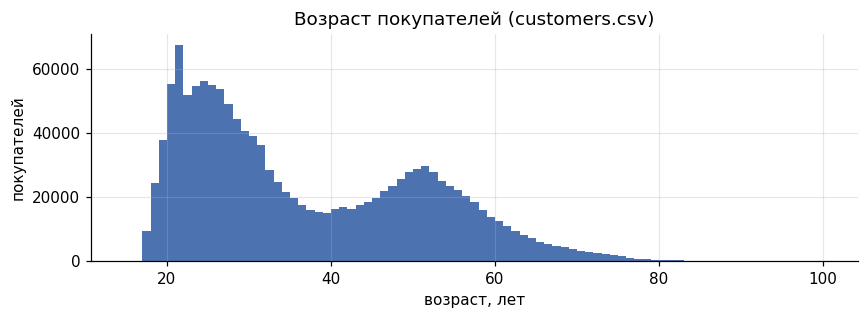

In [8]:
ages = con.sql("SELECT age FROM customers WHERE age IS NOT NULL").df()["age"]
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(ages, bins=range(15, 101), color="#4C72B0")
ax.set_title("Возраст покупателей (customers.csv)")
ax.set_xlabel("возраст, лет"); ax.set_ylabel("покупателей")
plt.tight_layout(); plt.show()

### 2.4 Выбросы

Цены нормированы, поэтому порог вроде «дороже 10 000» не поставить. Проверяю двумя способами:
- межквартильный размах по логарифму цены (выбросы относительно всех покупок);
- цена отличается от медианной цены того же артикула больше чем в 5 раз. Даже сильная распродажа даёт скидку меньше 80 %, так что такой разброс больше похож на ошибку в данных.

In [9]:
q1, q3 = con.sql("SELECT quantile_cont(ln(price), 0.25), quantile_cont(ln(price), 0.75) FROM tx").fetchone()
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
out = con.sql(f'''
    WITH med AS (SELECT article_id, median(price) AS m FROM tx GROUP BY 1)
    SELECT AVG(CASE WHEN ln(price) < {lo} OR ln(price) > {hi} THEN 1.0 ELSE 0 END) AS iqr_outlier_share,
           AVG(CASE WHEN price > 5 * m OR price < m / 5 THEN 1.0 ELSE 0 END) AS article_price_anomaly_share,
           SUM(CASE WHEN price > 5 * m OR price < m / 5 THEN 1 ELSE 0 END) AS article_price_anomaly_rows
    FROM tx JOIN med USING (article_id)''').df().T[0]
print(f"Границы IQR по цене: [{np.exp(lo):.5f}; {np.exp(hi):.5f}]")
print(out.to_string())

Границы IQR по цене: [0.00504; 0.10626]
iqr_outlier_share             0.0213
article_price_anomaly_share   0.0023
article_price_anomaly_rows    73,433


Выбросов по IQR 2,1 %, цен, сильно отличающихся от медианы артикула, 0,23 % (73 тыс. строк). Из выручки я их не убираю: проверить, ошибка это или настоящая скидка, нечем, а доля мала.

### 2.5 Тестовые и нерозничные покупатели

Явных тестовых записей нет: все покупатели из транзакций есть в справочнике (видно выше). Поэтому ищу по поведению. Покупатель, который берёт 100 и больше вещей за один день, скорее оптовик, сотрудник или тестовый аккаунт. Таких я убираю из продуктовых метрик, а в проверке качества они остаются.

Здесь же собирается таблица заказов. Номера чека нет, поэтому заказ это все покупки одного человека за один день.

In [10]:
# заказ = все покупки человека за день; канал заказа - тот, где сумма больше
con.execute("""
    CREATE OR REPLACE TABLE orders_all AS
    SELECT customer_id, t_dat, COUNT(*) AS items, SUM(price) AS rev,
           CASE WHEN SUM(CASE WHEN sales_channel_id = 2 THEN price ELSE 0 END)
                   > SUM(CASE WHEN sales_channel_id = 1 THEN price ELSE 0 END) THEN 2 ELSE 1 END AS ch
    FROM tx GROUP BY 1, 2""")
con.execute(f"""
    CREATE OR REPLACE TABLE test_users AS
    SELECT customer_id, MAX(items) AS max_items_per_day
    FROM orders_all GROUP BY 1 HAVING MAX(items) >= {TEST_ITEMS_PER_DAY}""")
# дальше везде используем orders - заказы без тестовых покупателей
con.execute("""
    CREATE OR REPLACE VIEW orders AS
    SELECT * FROM orders_all WHERE customer_id NOT IN (SELECT customer_id FROM test_users)""")

print(con.sql("""
    SELECT COUNT(*) AS orders, AVG(items) AS items_mean, quantile_cont(items, 0.99) AS items_p99,
           quantile_cont(items, 0.9999) AS items_p9999, MAX(items) AS items_max
    FROM orders_all""").df().T[0].to_string())
tu = con.sql("""
    SELECT COUNT(*) AS test_users,
           (SELECT COUNT(*) FROM tx WHERE customer_id IN (SELECT customer_id FROM test_users)) AS their_rows
    FROM test_users""").df().T[0]
print(tu.to_string())

orders        9,080,179
items_mean       3.5008
items_p99            18
items_p9999          53
items_max           570
test_users       88
their_rows    23350


### 2.6 Границы времени

- Данные начинаются 20.09.2018, поэтому все, кто покупал и раньше, в первые месяцы выглядят «новыми»: 40 % покупателей впервые появляются в первые 90 дней. Из-за этого прогрева когорты беру только с сентября 2019, когда за каждым уже есть год истории.
- Последний день 22.09.2020 (вторник), сентябрь 2020 неполный, в месячные метрики он не входит.
- Для правил с окном вперёд (конверсия и отток за 90 дней) беру только тех, у кого после события прошло 90 дней.
- В марте–мае 2020 магазины закрывались из-за пандемии, поведение в эти месяцы нетипичное, поэтому базовые уровни считаю до марта 2020.

Дней без данных внутри периода: 0
Последний день: 2020-09-22 (Tuesday)
Доля покупателей с первой покупкой в первые 90 дней данных: 40.1%


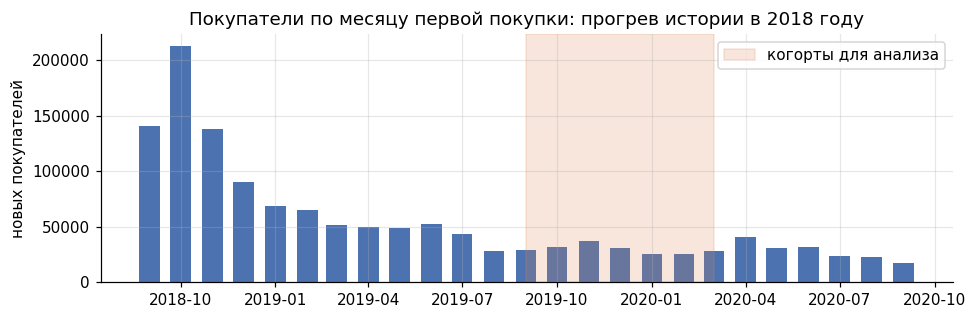

In [11]:
newm = con.sql('''
    WITH f AS (SELECT customer_id, MIN(t_dat) AS first_d FROM orders GROUP BY 1)
    SELECT CAST(date_trunc('month', first_d) AS DATE) AS month, COUNT(*) AS new_customers
    FROM f GROUP BY 1 ORDER BY 1''').df()
gap = con.sql('''
    SELECT date_diff('day', MIN(t_dat), MAX(t_dat)) + 1 - COUNT(DISTINCT t_dat) FROM tx''').fetchone()[0]
warm = con.sql(f'''
    WITH f AS (SELECT customer_id, MIN(t_dat) AS first_d FROM orders GROUP BY 1)
    SELECT AVG(CASE WHEN first_d < DATE '{MIN_DATE.date()}' + INTERVAL 90 DAY THEN 1.0 ELSE 0 END) FROM f''').fetchone()[0]
print(f"Дней без данных внутри периода: {gap}")
print(f"Последний день: {MAX_DATE.date()} ({MAX_DATE.day_name()})")
print(f"Доля покупателей с первой покупкой в первые 90 дней данных: {warm:.1%}")

fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(newm["month"], newm["new_customers"], width=20, color="#4C72B0")
ax.axvspan(pd.Timestamp(COHORT_START), pd.Timestamp(COHORT_END), color="#DD8452", alpha=0.2,
           label="когорты для анализа")
ax.set_title("Покупатели по месяцу первой покупки: прогрев истории в 2018 году")
ax.set_ylabel("новых покупателей"); ax.legend()
plt.tight_layout(); plt.show()

### 2.7 Итог по дефектам

По заданию дефектов должно быть не больше 5 %. Синтетические дефекты я не добавлял: естественных хватает, чтобы показать очистку.

In [12]:
def share(sql):
    return con.sql(sql).fetchone()[0]

defects = pd.DataFrame([
    ("customers", "age пустой", share("SELECT AVG(CASE WHEN age IS NULL THEN 1.0 ELSE 0 END) FROM customers"),
     "не используем возраст в этих срезах, отдельная категория «нет данных»"),
    ("customers", "club_member_status пустой", share("SELECT AVG(CASE WHEN club_member_status IS NULL THEN 1.0 ELSE 0 END) FROM customers"),
     "категория «нет данных»"),
    ("customers", "fashion_news_frequency пустой", share("SELECT AVG(CASE WHEN fashion_news_frequency IS NULL THEN 1.0 ELSE 0 END) FROM customers"),
     "категория «нет данных»"),
    ("customers", "fashion_news_frequency: 'None' и 'NONE'", share("SELECT AVG(CASE WHEN fashion_news_frequency = 'None' THEN 1.0 ELSE 0 END) FROM customers"),
     "приводим к одному значению NONE"),
    ("customers", "postal_code заглушка (один хеш)", share("SELECT MAX(n) * 1.0 / SUM(n) FROM (SELECT COUNT(*) n FROM customers GROUP BY postal_code)"),
     "не ключевое поле; гео-срез не строим"),
    ("articles", "garment_group = Unknown", share("SELECT AVG(CASE WHEN garment_group_name = 'Unknown' THEN 1.0 ELSE 0 END) FROM articles"),
     "отдельная группа, средняя маржа"),
    ("articles", "product_type_no = -1", share("SELECT AVG(CASE WHEN product_type_no = -1 THEN 1.0 ELSE 0 END) FROM articles"),
     "оставляем, на метрики не влияет"),
    ("tx", "ключевые поля пустые", share('''SELECT AVG(CASE WHEN t_dat IS NULL OR customer_id IS NULL OR article_id IS NULL
                                              OR price IS NULL OR sales_channel_id IS NULL THEN 1.0 ELSE 0 END) FROM tx'''),
     "не требуется"),
    ("tx", "товар неизвестного типа", share('''SELECT AVG(CASE WHEN a.product_type_no = -1 THEN 1.0 ELSE 0 END)
                                              FROM tx JOIN articles a USING (article_id)'''),
     "оставляем"),
    ("tx", "цена в 5+ раз от медианы артикула", out["article_price_anomaly_share"],
     "оставляем в выручке, проверить невозможно"),
    ("tx", "строки тестовых/оптовых покупателей", tu["their_rows"] / ov.loc["rows", "значение"],
     "исключаем из метрик"),
], columns=["таблица", "дефект", "доля", "решение"])
defects["доля, %"] = (defects.pop("доля") * 100).round(2)
print(defects[["таблица", "дефект", "доля, %", "решение"]].to_string(index=False, float_format=lambda x: f"{x:.2f}"))

tx_any = share(f'''
    WITH med AS (SELECT article_id, median(price) AS m FROM tx GROUP BY 1)
    SELECT AVG(CASE WHEN a.product_type_no = -1 OR price > 5 * m OR price < m / 5
                     OR customer_id IN (SELECT customer_id FROM test_users) THEN 1.0 ELSE 0 END)
    FROM tx JOIN med USING (article_id) JOIN articles a USING (article_id)''')
print(f"\nСтроки покупок хотя бы с одним дефектом: {tx_any:.2%} (порог задания - до 5 %)")

  таблица                                  дефект  доля, %                                                               решение
customers                              age пустой     1.16 не используем возраст в этих срезах, отдельная категория «нет данных»
customers               club_member_status пустой     0.44                                                категория «нет данных»
customers           fashion_news_frequency пустой     1.17                                                категория «нет данных»
customers fashion_news_frequency: 'None' и 'NONE'     0.00                                       приводим к одному значению NONE
customers         postal_code заглушка (один хеш)     8.77                                  не ключевое поле; гео-срез не строим
 articles                 garment_group = Unknown     3.67                                       отдельная группа, средняя маржа
 articles                    product_type_no = -1     0.11                                       


Строки покупок хотя бы с одним дефектом: 0.61% (порог задания - до 5 %)


Расхождение `'None'` и `'NONE'` в `fashion_news_frequency` касается всего двух строк. Пустых значений там 16 009, они учтены строкой выше.

Почему датасет подходит. У каждой покупки есть `customer_id`, поэтому строятся когорты, LTV и сегменты. Данных за два года (два полных сезона) и 1,36 млн покупателей. Отток определяется по датам покупок, а деньги берутся из цены каждой вещи. Данные настоящие: распределения скошены, есть выбросы цены, пропуски и несостыковки в справочниках. Чего в данных не хватает, описано в разделе 9.

## 3. Определения

Определения фиксируются здесь и дальше не меняются. Числовые параметры (окна, границы когорт) заданы в ячейке настройки.

| Понятие | Как считается |
|---|---|
| Покупатель | `customer_id`, кроме тестовых/оптовых (100+ вещей за один день) |
| Заказ | все покупки покупателя за один календарный день |
| Канал покупателя | канал его первого заказа; канал заказа = канал, где в этот день сумма больше (при равенстве 1) |
| Дата появления | дата первого заказа (даты регистрации в данных нет) |
| Активный покупатель | сделал хотя бы один заказ в календарном месяце |
| Повторный покупатель месяца | активен в месяце и уже покупал в течение 365 дней до начала месяца |
| Конверсия | доля новых покупателей, сделавших второй заказ (в другой день) за 90 дней после первого. Просмотров и корзины нет, поэтому это конверсия в повторную покупку |
| Когорта | месяц первого заказа; в анализе когорты с сентября 2019 по февраль 2020 |
| Удержание (retention) месяца k | доля когорты, у которой есть заказ в месяце «месяц когорты + k», k = 0…6 |
| Отток | с последнего заказа прошло больше 90 дней. Для всей базы считается на конец данных. Для месячной метрики пирамиды: активный в месяце покупатель ушёл, если в 90 дней после конца месяца у него нет заказа. Считается только там, где есть 90 дней наблюдения |
| Выручка | `price × 1000`, в условных единицах (у.е.) |
| LTV (месяцы 0–6) | накопленная валовая прибыль на одного покупателя когорты к концу месяца k |

In [13]:
# по строке на покупателя: первый, второй и последний заказ, канал, когорта
con.execute("""
    CREATE OR REPLACE TABLE cust AS
    WITH o AS (SELECT *, row_number() OVER (PARTITION BY customer_id ORDER BY t_dat) AS n FROM orders)
    SELECT o.customer_id,
           MIN(t_dat) AS first_d, MAX(t_dat) AS last_d, COUNT(*) AS n_orders,
           MAX(CASE WHEN n = 2 THEN t_dat END) AS second_d,
           MAX(CASE WHEN n = 1 THEN ch END) AS first_ch,
           CAST(date_trunc('month', MIN(t_dat)) AS DATE) AS cohort
    FROM o GROUP BY 1""")

churn = con.sql(f"""
    SELECT COUNT(*) AS eligible,
           SUM(CASE WHEN last_d < DATE '{MAX_DATE.date()}' - INTERVAL {CHURN_DAYS} DAY THEN 1 ELSE 0 END) AS churned
    FROM cust WHERE first_d <= DATE '{MAX_DATE.date()}' - INTERVAL {CHURN_DAYS} DAY""").df().T[0]
churn["churn_share"] = churn["churned"] / churn["eligible"]
print("Отток по правилу «нет покупок 90 дней» на конец данных:")
print(churn.to_string())

Отток по правилу «нет покупок 90 дней» на конец данных:
eligible      1,291,060
churned         837,161
churn_share      0.6484


На конец данных ушли 64,8 % покупателей. Это доля среди всех, кто когда-либо покупал, включая разовых покупателей двухлетней давности. В пирамиде отток считается среди активных в месяце (раздел 4), там он 30–39 %, потому что активные в основном постоянные: повторные покупатели составляют 85–88 % активных. Это два разных числа, и сравнивать их нельзя.

## 4. Метрики

```
                    North Star: повторные покупатели в месяц
                  (покупали в месяце и в предыдущие 365 дней)
                    /                                    \
   Диагностическая 1:                          Диагностическая 2:
   конверсия новых во второй заказ             средний чек заказа, у.е.
   за 90 дней (приток в North Star)            (сколько приносит заказ)
                    \                                    /
              Риск-метрика: отток 90 дней среди активных
```

| Уровень | Метрика | Почему именно она | Какое решение на неё опирается |
|---|---|---|---|
| North Star | Повторные покупатели в месяц | Показывает, что человек нашёл нужное и вернулся. Новые покупатели от рекламы в неё не попадают, пока не купят снова | Куда вкладывать усилия: в удержание или в привлечение |
| Диагностическая | Конверсия во второй заказ за 90 дней | Главный приток в North Star: новый покупатель становится повторным. На неё нацелена гипотеза про рекомендации | Запускать ли рекомендации для новых; вместе с LTV/CAC решает, как делить бюджет между каналами |
| Диагностическая | Средний чек заказа | Следит, чтобы повторных покупателей не становилось больше за счёт мелких чеков. Связывает North Star с выручкой и LTV | Допродажи в корзине, блок «дополните образ» |
| Риск | Отток 90 дней среди активных в месяце | Ранний сигнал, что база уходит. Нужен, чтобы не принять решение, которое разово поднимает продажи (скидки), но портит удержание | Стоп-критерий для экспериментов, запуск реактивации |

### Почему не DAU, воронка и выручка

Одежду покупают редко: у покупателя в среднем 6,7 заказа за два года, то есть примерно один в квартал, и 3,5 вещи в заказе. Поэтому привычные метрики приложений не подходят.

| Метрика | Почему не подходит |
|---|---|
| DAU, retention 1-го дня или недели | одежду не покупают каждый день, почти все были бы «неактивными». Вместо этого месячная активность и окна по 90 дней |
| Конверсия визит → покупка, воронка | визитов, просмотров и корзины в данных нет |
| Время в приложении, сессии, клики по рекомендациям | таких событий тоже нет |
| Выручка как North Star | растёт от скидок и рекламы, даже если покупателям стало хуже |

Окно 90 дней выбрано под эту частоту покупок: с окном 30 дней «ушедшими» считались бы люди, которые просто ещё не пришли за следующей покупкой.

Ниже все четыре метрики по месяцам. В таблице только полные месяцы. North Star считается с сентября 2019, потому что нужен год истории, а отток только там, где после месяца есть 90 дней наблюдения.

In [14]:
monthly = con.sql(f"""
    WITH o AS (
        SELECT customer_id, t_dat, rev,
               lag(t_dat)  OVER w AS prev_d,
               lead(t_dat) OVER w AS next_d,
               CAST(date_trunc('month', t_dat) AS DATE) AS m
        FROM orders WINDOW w AS (PARTITION BY customer_id ORDER BY t_dat)),
    bm AS (
        SELECT customer_id, m, COUNT(*) AS orders, SUM(rev) AS rev,
               bool_or(prev_d < m AND prev_d >= m - INTERVAL {RETURN_LOOKBACK_DAYS} DAY) AS is_ret,
               bool_or(next_d > last_day(m) AND next_d <= last_day(m) + INTERVAL {CHURN_DAYS} DAY) AS came_back
        FROM o GROUP BY 1, 2)
    SELECT m AS month, COUNT(*) AS active, SUM(CASE WHEN is_ret THEN 1 ELSE 0 END) AS "returning",
           SUM(orders) AS orders, SUM(rev) * {PRICE_SCALE} AS revenue,
           SUM(rev) * {PRICE_SCALE} / SUM(orders) AS aov,
           1 - AVG(CASE WHEN came_back THEN 1.0 ELSE 0 END) AS churn90
    FROM bm GROUP BY 1 ORDER BY 1""").df()
monthly["month"] = pd.to_datetime(monthly["month"])

# последний полный месяц (сентябрь 2020 обрывается 22-го числа)
last_full_month = (MAX_DATE + pd.Timedelta(days=1)).to_period("M").start_time - pd.offsets.MonthBegin(1)
monthly.loc[monthly["month"] < COHORT_START, "returning"] = np.nan   # до сен 2019 мало истории
monthly.loc[monthly["month"] > last_full_month, ["active", "returning", "orders", "revenue", "aov"]] = np.nan
# отток месяца известен, только если после конца месяца есть 90 дней данных
no_churn_data = monthly["month"] + pd.offsets.MonthEnd(0) + pd.Timedelta(days=CHURN_DAYS) > MAX_DATE
monthly.loc[no_churn_data, "churn90"] = np.nan

conv = con.sql(f"""
    SELECT cohort AS month, COUNT(*) AS new_customers,
           AVG(CASE WHEN second_d <= first_d + INTERVAL {CONVERSION_DAYS} DAY THEN 1.0 ELSE 0 END) AS conv90
    FROM cust
    WHERE first_d >= DATE '{COHORT_START}'
      AND first_d <= DATE '{MAX_DATE.date()}' - INTERVAL {CONVERSION_DAYS} DAY
    GROUP BY 1 ORDER BY 1""").df()
conv["month"] = pd.to_datetime(conv["month"])
metrics = monthly.merge(conv, on="month", how="left")
show = metrics[metrics["month"] >= COHORT_START].copy()
show["month"] = show["month"].dt.strftime("%Y-%m")
print(show.to_string(index=False, float_format=lambda x: f"{x:,.3f}"))

  month      active   returning      orders        revenue     aov  churn90  new_customers  conv90
2019-09 244,020.000 215,045.000 353,452.000 40,268,171.695 113.928    0.299     28,975.000   0.358
2019-10 254,113.000 221,889.000 364,115.000 36,959,795.712 101.506    0.326     31,626.000   0.325
2019-11 270,041.000 230,923.000 389,619.000 38,827,215.847  99.654    0.351     36,989.000   0.310
2019-12 262,227.000 228,480.000 381,347.000 31,248,398.644  81.942    0.374     30,579.000   0.298
2020-01 230,988.000 202,464.000 326,683.000 28,773,469.475  88.078    0.377     25,130.000   0.308
2020-02 226,826.000 197,603.000 314,764.000 28,769,758.475  91.401    0.393     25,060.000   0.298
2020-03 212,224.000 179,093.000 290,056.000 30,264,718.237 104.341    0.335     28,242.000   0.328
2020-04 228,690.000 180,924.000 307,003.000 37,782,706.814 123.070    0.367     40,687.000   0.324
2020-05 247,159.000 209,437.000 362,690.000 37,128,821.288 102.371    0.314     30,518.000   0.363
2020-06 30

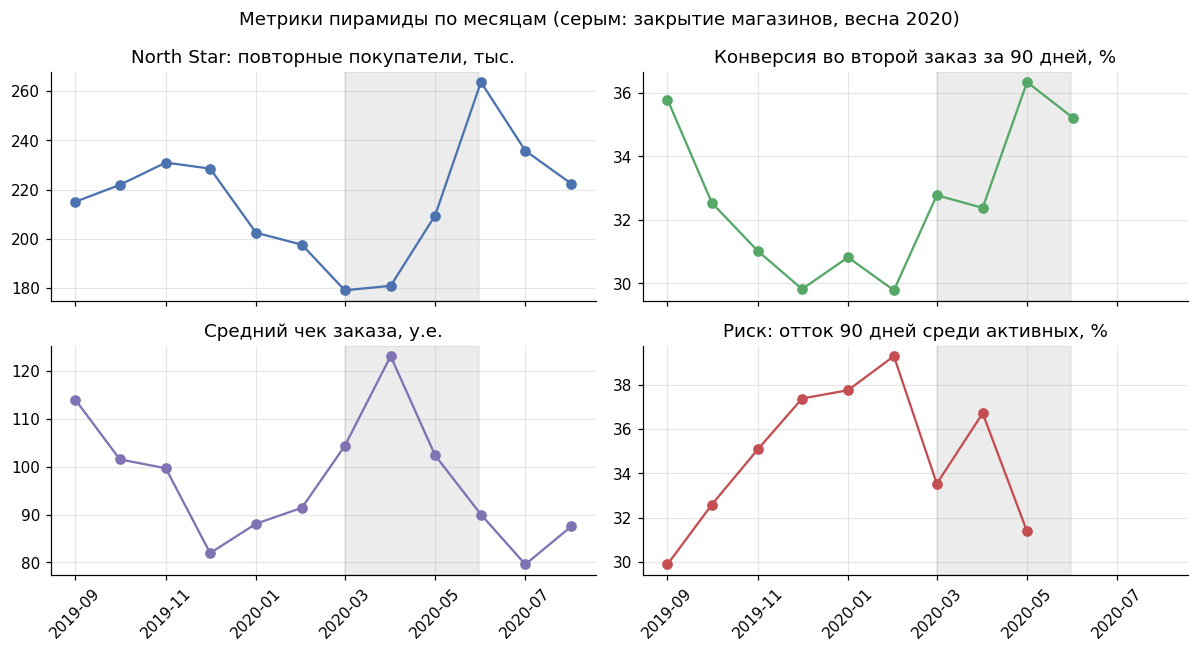

In [15]:
m = metrics.dropna(subset=["returning"])
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
axes[0, 0].plot(m["month"], m["returning"] / 1e3, marker="o", color="#4C72B0")
axes[0, 0].set_title("North Star: повторные покупатели, тыс.")
c = metrics.dropna(subset=["conv90"])
axes[0, 1].plot(c["month"], c["conv90"] * 100, marker="o", color="#55A868")
axes[0, 1].set_title("Конверсия во второй заказ за 90 дней, %")
axes[1, 0].plot(m["month"], m["aov"], marker="o", color="#8172B3")
axes[1, 0].set_title("Средний чек заказа, у.е.")
r = metrics.dropna(subset=["churn90"])
r = r[r["month"] >= m["month"].min()]
axes[1, 1].plot(r["month"], r["churn90"] * 100, marker="o", color="#C44E52")
axes[1, 1].set_title("Риск: отток 90 дней среди активных, %")
for ax in axes.flat:
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-05-31"), color="grey", alpha=0.15)
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Метрики пирамиды по месяцам (серым: закрытие магазинов, весна 2020)")
plt.tight_layout(); plt.show()

North Star колеблется от 179 до 236 тыс. повторных покупателей в месяц, исключение июнь 2020 с пиком 264 тыс. (скорее всего отложенный спрос после закрытия магазинов, по данным причину не проверить). Конверсия во второй заказ держится на уровне 30–36 %, средний чек колеблется от 80 до 123 у.е., отток 90 дней среди активных от 30 до 39 %.

## 5. План трекинга

Сырое событие в данных одно, строка покупки. Остальные события я восстанавливаю из транзакций по определениям раздела 3. В живом продукте их отправлял бы трекинг, а здесь каждое однозначно получается из полей датасета. Для трека Б нужно минимум три события, у меня пять.

In [16]:
tracking = pd.DataFrame([
    ("item_purchased", "строка покупки в чеке",
     "customer_id, article_id, price, sales_channel_id, t_dat",
     "выручка, валовая прибыль, LTV", "покупка",
     "transactions_train: все поля; articles.garment_group_name"),
    ("order_completed", "все покупки покупателя за календарный день",
     "customer_id, t_dat, items, order_value, channel",
     "средний чек (диагн. 2), активные покупатели", "покупка",
     "transactions_train: t_dat, customer_id, price, sales_channel_id"),
    ("first_purchase", "первый order_completed покупателя",
     "customer_id, first_date, first_channel, age, club_member_status",
     "новые покупатели, когорта, CAC", "привлечение",
     "MIN(t_dat), sales_channel_id; customers.age, club_member_status"),
    ("repeat_purchase", "order_completed, перед которым был заказ этого покупателя",
     "customer_id, order_number, days_since_prev",
     "North Star, конверсия (диагн. 1), retention", "возврат",
     "t_dat (порядок и разница дат по customer_id)"),
    ("churned", "прошло 90 дней без order_completed",
     "customer_id, last_date, n_orders, ltv",
     "риск-метрика: доля оттока", "отток",
     "MAX(t_dat) по customer_id и дата конца данных"),
], columns=["событие", "триггер", "параметры", "метрика", "этап пути", "поле датасета"])
print(tracking.to_string(index=False))

        событие                                                   триггер                                                       параметры                                     метрика   этап пути                                                   поле датасета
 item_purchased                                     строка покупки в чеке         customer_id, article_id, price, sales_channel_id, t_dat               выручка, валовая прибыль, LTV     покупка       transactions_train: все поля; articles.garment_group_name
order_completed                все покупки покупателя за календарный день                 customer_id, t_dat, items, order_value, channel средний чек (диагн. 2), активные покупатели     покупка transactions_train: t_dat, customer_id, price, sales_channel_id
 first_purchase                         первый order_completed покупателя customer_id, first_date, first_channel, age, club_member_status              новые покупатели, когорта, CAC привлечение MIN(t_dat), sales_channel_id; cu

In [17]:
# проверка: сколько событий каждого типа получается из данных (без тестовых покупателей)
ev = con.sql(f"""
    SELECT
      (SELECT COUNT(*) FROM tx WHERE customer_id NOT IN (SELECT customer_id FROM test_users)) AS item_purchased,
      (SELECT COUNT(*) FROM orders) AS order_completed,
      (SELECT COUNT(*) FROM cust) AS first_purchase,
      (SELECT COUNT(*) FROM orders) - (SELECT COUNT(*) FROM cust) AS repeat_purchase,
      (SELECT COUNT(*) FROM cust WHERE last_d < DATE '{MAX_DATE.date()}' - INTERVAL {CHURN_DAYS} DAY) AS churned
""").df().T
ev.columns = ["событий"]
print(ev.to_string(formatters={"событий": "{:,}".format}))

                   событий
item_purchased  31,764,974
order_completed  9,078,860
first_purchase   1,362,193
repeat_purchase  7,716,667
churned            837,161


## 6. Первые расчёты

### 6.1 Когортный retention

Когорты по месяцу первого заказа, с сентября 2019 по февраль 2020. Для каждой есть полные 6 месяцев наблюдения (у февральской последний месяц август 2020).

k        размер     0     1     2     3     4     5     6
cohort                                                   
2019-09   28975 1.000 0.160 0.141 0.136 0.111 0.108 0.102
2019-10   31626 1.000 0.149 0.130 0.103 0.104 0.092 0.096
2019-11   36989 1.000 0.142 0.104 0.100 0.090 0.092 0.100
2019-12   30579 1.000 0.123 0.109 0.090 0.095 0.105 0.135
2020-01   25130 1.000 0.127 0.105 0.108 0.108 0.133 0.116
2020-02   25060 1.000 0.118 0.105 0.110 0.134 0.114 0.103


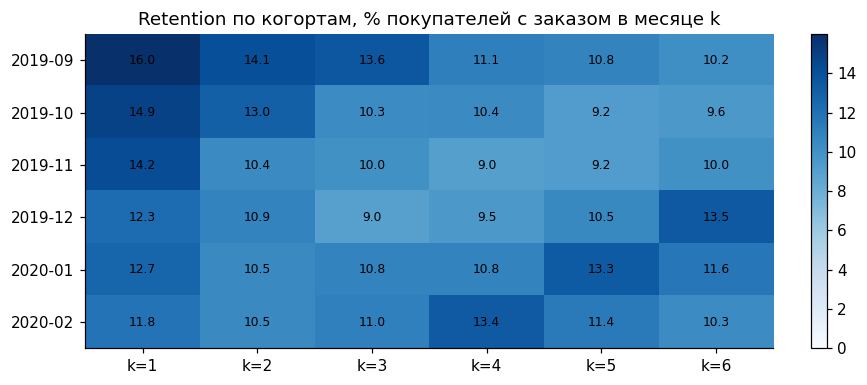

In [18]:
coh = con.sql(f'''
    SELECT c.cohort, c.first_ch,
           date_diff('month', c.cohort, CAST(date_trunc('month', o.t_dat) AS DATE)) AS k,
           COUNT(DISTINCT o.customer_id) AS active
    FROM orders o JOIN cust c USING (customer_id)
    WHERE c.cohort >= DATE '{COHORT_START}' AND c.cohort < DATE '{COHORT_END}'
    GROUP BY 1, 2, 3 HAVING k BETWEEN 0 AND {MAX_K}''').df()

act = coh.groupby(["cohort", "k"])["active"].sum().unstack("k")
sizes = act[0]
ret = act.div(sizes, axis=0)
ret.index = pd.to_datetime(ret.index).strftime("%Y-%m")
table = ret.copy()
table.insert(0, "размер", sizes.values)
print(table.to_string(float_format=lambda x: f"{x:.3f}"))

fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(ret.iloc[:, 1:].values * 100, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(MAX_K)); ax.set_xticklabels([f"k={k}" for k in range(1, MAX_K + 1)])
ax.set_yticks(range(len(ret))); ax.set_yticklabels(ret.index)
for i in range(len(ret)):
    for j in range(MAX_K):
        ax.text(j, i, f"{ret.iloc[i, j + 1] * 100:.1f}", ha="center", va="center", fontsize=8)
ax.set_title("Retention по когортам, % покупателей с заказом в месяце k"); ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.03); plt.tight_layout(); plt.show()

k         0      1      2      3      4      5      6
first_ch                                             
1         1 0.1610 0.1310 0.1190 0.1150 0.1150 0.1180
2         1 0.1280 0.1090 0.1020 0.1020 0.1020 0.1040


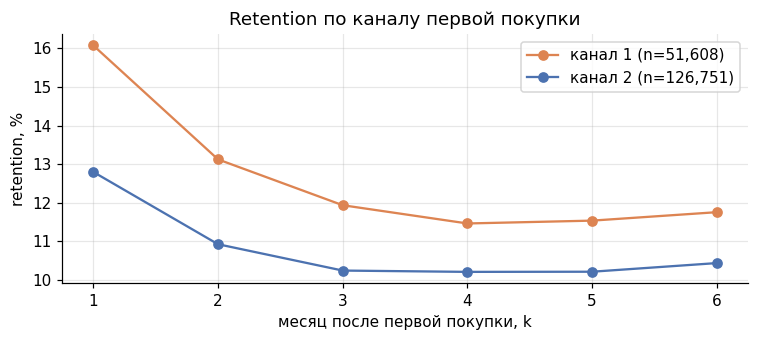

Retention месяца 1: от 11.8% до 16.0%; месяц 3 в среднем 10.8%, месяц 6 - 10.9%


In [19]:
# retention по каналу первой покупки, все шесть когорт вместе
by_ch = coh.groupby(["first_ch", "k"])["active"].sum().unstack("k")
ret_ch = by_ch.div(by_ch[0], axis=0)
print(ret_ch.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 3.2))
for ch, color in [(1, "#DD8452"), (2, "#4C72B0")]:
    ax.plot(range(1, MAX_K + 1), ret_ch.loc[ch, 1:] * 100, marker="o", color=color,
            label=f"канал {ch} (n={int(by_ch.loc[ch, 0]):,})")
ax.set_xlabel("месяц после первой покупки, k"); ax.set_ylabel("retention, %")
ax.set_title("Retention по каналу первой покупки"); ax.legend()
plt.tight_layout(); plt.show()

r1 = ret[1]
print(f"Retention месяца 1: от {r1.min():.1%} до {r1.max():.1%}; "
      f"месяц 3 в среднем {ret[3].mean():.1%}, месяц 6 - {ret[6].mean():.1%}")

Выводы по retention

- Удержание низкое и быстро выходит на плато. В первый месяц после первой покупки возвращаются 12–16 % новых покупателей, к третьему около 11 %, дальше почти без изменений. Больше всего людей теряется сразу после первой покупки, поэтому гипотеза про рекомендации (раздел 1) нацелена именно на этот момент.
- У поздних когорт первый месяц слабее: у сентябрьской 16 %, у февральской 11,8 %. Отчасти это сезон, январь и февраль для покупок слабые.
- У зимних когорт retention растёт в месяцах 4–6 (у декабрьской до 13,5 %). Все эти значения приходятся на июнь 2020, когда был общий пик покупок, так что дело, скорее всего, не в продукте. Когорты нужно сравнивать в одном календарном месяце, а не только по возрасту, тем более что весна 2020 попадает в окно наблюдения осенних когорт.
- Разница между каналами есть в самих данных, к генерации она отношения не имеет. Покупатели канала 1 возвращаются чаще: 16,1 % против 12,8 % в первый месяц и 11,8 % против 10,4 % к шестому. Зато LTV выше у канала 2, потому что у них крупнее первый заказ (6.4). Значит, каналы надо оценивать по двум вещам сразу: удержанию и размеру первого заказа.

### 6.2 Маржа (сгенерирована)

Себестоимости в данных нет, а без маржи LTV получится просто выручкой. Поэтому маржу генерирую по реальной структуре ассортимента:
1. Каждой из 21 группы одежды задаю относительный уровень маржи: базовые вещи и аксессуары выше, верхняя одежда и обувь ниже, раздел распродажи намного ниже.
2. Уровни масштабирую так, чтобы средняя маржа с весами по реальной выручке групп совпала с валовой маржой H&M Group за 2019 финансовый год, 52,6 % (годовой отчёт).
3. Каждому артикулу добавляю разброс: бета-распределение вокруг маржи группы со стандартным отклонением 0,05, seed фиксирован.

In [20]:
TARGET_GROSS_MARGIN = 0.526   # H&M Group, 2019 финансовый год (1.12.2018 - 30.11.2019)
MARGIN_SD = 0.05
# относительный уровень маржи группы, потом масштабируется к 52.6 %
REL_MARGIN = {
    "Accessories": 1.15, "Socks and Tights": 1.12, "Jersey Basic": 1.10, "Under-, Nightwear": 1.08,
    "Jersey Fancy": 1.04, "Swimwear": 1.04, "Blouses": 1.02, "Dresses Ladies": 1.02, "Shirts": 1.00,
    "Skirts": 1.00, "Dressed": 0.98, "Knitwear": 0.98, "Shorts": 0.98, "Dresses/Skirts girls": 0.97,
    "Trousers": 0.95, "Woven/Jersey/Knitted mix Baby": 0.95, "Unknown": 0.95, "Trousers Denim": 0.92,
    "Outdoor": 0.88, "Shoes": 0.85, "Special Offers": 0.60,
}

grp = con.sql(f"""
    SELECT a.garment_group_name AS grp, COUNT(DISTINCT a.article_id) AS articles, SUM(t.price) AS rev
    FROM tx t JOIN articles a USING (article_id)
    WHERE t.t_dat >= DATE '{COHORT_START}' GROUP BY 1""").df()
print("Группы без заданного уровня (берётся 1.0):", sorted(set(grp["grp"]) - set(REL_MARGIN)) or "нет")
grp["rel"] = grp["grp"].map(REL_MARGIN).fillna(1.0)
grp["w"] = grp["rev"] / grp["rev"].sum()
scale = TARGET_GROSS_MARGIN / (grp["w"] * grp["rel"]).sum()
grp["margin"] = (grp["rel"] * scale).clip(0.05, 0.90)

# маржа артикула ~ Beta со средним = маржа группы и sd = MARGIN_SD
rng = np.random.default_rng(SEED)
art = con.sql("SELECT article_id, garment_group_name AS grp FROM articles").df()
mean_m = art["grp"].map(grp.set_index("grp")["margin"]).fillna(TARGET_GROSS_MARGIN).values
kappa = mean_m * (1 - mean_m) / MARGIN_SD ** 2 - 1
art["margin"] = rng.beta(mean_m * kappa, (1 - mean_m) * kappa)
con.register("art_margin_df", art[["article_id", "margin"]])
con.execute("CREATE OR REPLACE TABLE art_margin AS SELECT * FROM art_margin_df")

check = con.sql(f"""
    SELECT SUM(t.price * m.margin) / SUM(t.price) FROM tx t JOIN art_margin m USING (article_id)
    WHERE t.t_dat >= DATE '{COHORT_START}' """).fetchone()[0]
print(f"Средняя маржа, взвешенная по выручке, после генерации: {check:.1%} (цель {TARGET_GROSS_MARGIN:.1%})")
print(grp.sort_values("w", ascending=False)[["grp", "articles", "w", "margin"]]
      .rename(columns={"w": "доля выручки", "margin": "маржа"}).to_string(index=False, float_format=lambda x: f"{x:.3f}"))

Группы без заданного уровня (берётся 1.0): нет
Средняя маржа, взвешенная по выручке, после генерации: 52.6% (цель 52.6%)
                          grp  articles  доля выручки  маржа
                 Jersey Fancy     13992         0.138  0.547
                     Trousers      4785         0.115  0.500
                     Knitwear      5168         0.093  0.516
               Dresses Ladies      3632         0.085  0.537
            Under-, Nightwear      5172         0.080  0.568
                      Blouses      4378         0.079  0.537
                 Jersey Basic      5538         0.061  0.579
                      Outdoor      3105         0.059  0.463
               Trousers Denim      2317         0.059  0.484
                     Swimwear      2249         0.057  0.547
                        Shoes      3475         0.029  0.447
                      Dressed       635         0.028  0.516
                  Accessories      7840         0.028  0.605
                       Sk

### 6.3 Расходы на привлечение и CAC (сгенерированы)

Маркетинговых расходов в данных нет. Делаю дневную таблицу «дата × канал», привязанную к реальному числу новых покупателей:

`расход(день, канал) = новые покупатели канала за день × CAC_BASE × сезонный множитель × шум`

- CAC_BASE = 50 у.е., одинаковый для обоих каналов. Так разница между каналами в LTV/CAC целиком берётся из реального LTV, своей разницы я не добавляю. Настоящий CAC H&M не публикует, поэтому 50 это сценарий, а главный результат здесь таблица чувствительности в 6.4.
- В неделю Black Friday (22.11–02.12.2019) реклама дороже, множитель 1,3.
- Шум логнормальный, σ = 0,10 (бюджеты и аукционы колеблются день ото дня), seed 42.

Канал здесь означает канал первой покупки, то есть канал продаж, а не рекламный. Это ограничение допущения.

In [21]:
CAC_BASE = {1: 50.0, 2: 50.0}
BF_START, BF_END, BF_MULT = "2019-11-22", "2019-12-02", 1.3
NOISE_SD = 0.10

spend = con.sql(f"""
    SELECT first_d AS date, first_ch AS ch, COUNT(*) AS new_customers
    FROM cust WHERE first_d >= DATE '{COHORT_START}' AND first_d < DATE '{COHORT_END}'
    GROUP BY 1, 2 ORDER BY 1, 2""").df()
spend["date"] = pd.to_datetime(spend["date"])
rng = np.random.default_rng(SEED)
mult = np.where(spend["date"].between(BF_START, BF_END), BF_MULT, 1.0)
# mean = -sd^2/2, чтобы среднее шума было 1
noise = rng.lognormal(mean=-NOISE_SD ** 2 / 2, sigma=NOISE_SD, size=len(spend))
spend["spend"] = spend["new_customers"] * spend["ch"].map(CAC_BASE) * mult * noise
spend["is_synthetic"] = True
spend.to_csv(OUT_DIR / "hm_channel_daily_spend.csv", index=False)
print(f"Сохранено: {OUT_DIR / 'hm_channel_daily_spend.csv'} ({len(spend)} строк)")
print(spend.groupby("ch")[["new_customers", "spend"]].sum().assign(CAC=lambda d: d["spend"] / d["new_customers"]).round(2))

Сохранено: outputs/hm_channel_daily_spend.csv (364 строк)
    new_customers          spend     CAC
ch                                      
1           51608 2,685,731.6600 52.0400
2          126751 6,575,776.3400 51.8800


### 6.4 LTV и LTV/CAC

LTV здесь это накопленная валовая прибыль на покупателя когорты за месяцы 0–6 (выручка × сгенерированная маржа товара). Это оценка снизу: за 7 месяцев покупатель приносит меньше, чем принесёт за всё время.

In [22]:
ltv_raw = con.sql(f"""
    SELECT c.first_ch AS ch,
           date_diff('month', c.cohort, CAST(date_trunc('month', t.t_dat) AS DATE)) AS k,
           SUM(t.price) * {PRICE_SCALE} AS rev,
           SUM(t.price * COALESCE(m.margin, {TARGET_GROSS_MARGIN})) * {PRICE_SCALE} AS gp
    FROM tx t JOIN cust c USING (customer_id) LEFT JOIN art_margin m USING (article_id)
    WHERE c.cohort >= DATE '{COHORT_START}' AND c.cohort < DATE '{COHORT_END}'
    GROUP BY 1, 2 HAVING k BETWEEN 0 AND {MAX_K}""").df()

n_new = spend.groupby("ch")["new_customers"].sum()
rev_cum = ltv_raw.pivot(index="ch", columns="k", values="rev").fillna(0).cumsum(axis=1).div(n_new, axis=0)
gp_cum = ltv_raw.pivot(index="ch", columns="k", values="gp").fillna(0).cumsum(axis=1).div(n_new, axis=0)
print("LTV по выручке, у.е. на покупателя (накопленно):"); print(rev_cum.round(1).to_string())
print("\nLTV по валовой прибыли, у.е. на покупателя (накопленно):"); print(gp_cum.round(1).to_string())

cac = spend.groupby("ch")["spend"].sum() / n_new

def payback_month(ch):
    # первый месяц, к которому накопленная прибыль покрыла CAC
    for k in gp_cum.columns:
        if gp_cum.loc[ch, k] >= cac[ch]:
            return k
    return None

res = pd.DataFrame({
    "новых покупателей": n_new,
    "расход, у.е.": spend.groupby("ch")["spend"].sum().round(0),
    "CAC": cac.round(2),
    "LTV выручка 0-6": rev_cum[MAX_K].round(2),
    "LTV прибыль 0-6": gp_cum[MAX_K].round(2),
    "LTV/CAC": (gp_cum[MAX_K] / cac).round(2),
    "окупаемость, месяц": [payback_month(ch) for ch in gp_cum.index],
    "безубыточный CAC": gp_cum[MAX_K].round(2),
})
res.index.name = "канал"
print("\n", res.to_string())
res.to_csv(OUT_DIR / "hm_ltv_cac_by_channel.csv")

LTV по выручке, у.е. на покупателя (накопленно):
k        0        1        2        3        4        5        6
ch                                                              
1  87.5000 100.8000 112.5000 123.2000 134.4000 146.1000 158.1000
2      116      131 144.4000 156.9000 169.9000 183.4000      197

LTV по валовой прибыли, у.е. на покупателя (накопленно):
k        0       1       2       3       4       5        6
ch                                                         
1  45.9000 52.9000      59 64.7000 70.7000 76.9000  83.3000
2  60.3000 68.2000 75.2000 81.8000 88.7000 95.8000 103.1000

        новых покупателей  расход, у.е.     CAC  LTV выручка 0-6  LTV прибыль 0-6  LTV/CAC  окупаемость, месяц  безубыточный CAC
канал                                                                                                                          
1                  51608     2,685,732 52.0400         158.0700          83.2600   1.6000                   1           83.2600
2      

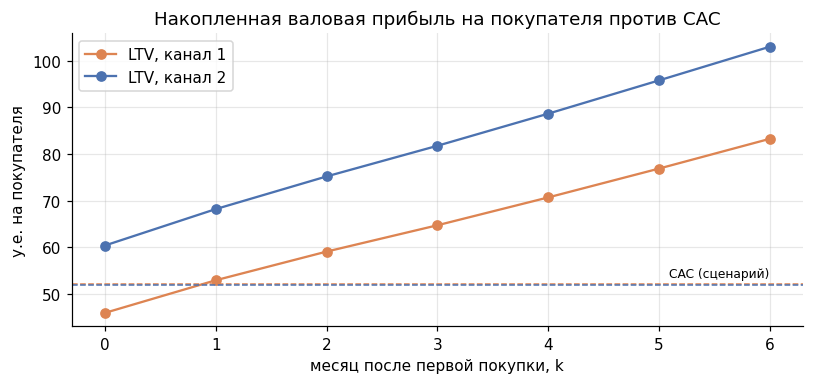

                  LTV/CAC канал 1           LTV/CAC канал 2          
сдвиг маржи, п.п.             -10   0    10             -10   0    10
CAC                                                                  
20                           3.37 4.16 4.95            4.17 5.15 6.14
35                           1.93 2.38 2.83            2.38 2.94 3.51
50                           1.35 1.67 1.98            1.67 2.06 2.46
65                           1.04 1.28 1.52            1.28 1.59 1.89
80                           0.84 1.04 1.24            1.04 1.29 1.53
100                          0.67 0.83 0.99            0.83 1.03 1.23


In [23]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for ch, color in [(1, "#DD8452"), (2, "#4C72B0")]:
    ax.plot(gp_cum.columns, gp_cum.loc[ch], marker="o", color=color, label=f"LTV, канал {ch}")
    ax.axhline(cac[ch], color=color, ls="--", lw=1)
ax.text(MAX_K, cac.mean() * 1.03, "CAC (сценарий)", ha="right", fontsize=8)
ax.set_xlabel("месяц после первой покупки, k"); ax.set_ylabel("у.е. на покупателя")
ax.set_title("Накопленная валовая прибыль на покупателя против CAC"); ax.legend()
plt.tight_layout(); plt.show()

# чувствительность: другой CAC и маржа +-10 п.п.
rows = []
for cac_v in [20, 35, 50, 65, 80, 100]:
    for dm in [-0.10, 0.0, 0.10]:
        row = {"CAC": cac_v, "сдвиг маржи, п.п.": int(round(dm * 100))}
        for ch in gp_cum.index:
            ltv_v = gp_cum.loc[ch, MAX_K] + dm * rev_cum.loc[ch, MAX_K]
            row[f"LTV/CAC канал {ch}"] = round(ltv_v / cac_v, 2)
        rows.append(row)
sens = pd.DataFrame(rows)
print(sens.pivot(index="CAC", columns="сдвиг маржи, п.п.").round(2).to_string(float_format=lambda x: f"{x:.2f}"))

Выводы по LTV/CAC

- Реальная часть результата здесь LTV. Покупатель канала 2 за 7 месяцев приносит примерно на четверть больше выручки и прибыли, чем покупатель канала 1, и почти три четверти этой разницы набегает в месяце 0, на первом заказе.
- Безубыточный CAC, то есть сколько можно потратить на привлечение, чтобы окупиться за месяцы 0–6, около 83 у.е. для канала 1 и 103 у.е. для канала 2. От сгенерированного CAC он не зависит.
- При CAC около 50 у.е. LTV/CAC равен 1,6 для канала 1 и 2,0 для канала 2. Канал 2 окупается первым же заказом (месяц 0), канал 1 к концу следующего месяца. По таблице чувствительности привлечение окупается при CAC до 80 у.е. в канале 1 и до 100 у.е. в канале 2, а сдвиг маржи на ±10 п.п. меняет LTV/CAC примерно на 0,3–0,4.
- Сами значения LTV/CAC верны только при допущении о CAC. Для решений надёжнее безубыточный CAC и сравнение каналов между собой.

## 7. Приватность и риски использования данных

Цель анализа учебная: выбрать продуктовые метрики и посчитать их на реальных данных. Решений про конкретных людей не принимается.

Данные выложила сама H&M Group для соревнования на Kaggle, сбор данных и согласие покупателей остаются на её стороне. Я использую их по правилам соревнования и не распространяю: в репозитории только код и агрегированные результаты.

ID покупателей и индексы захешированы, специальных категорий (здоровье, религия, политика и т. п.) в данных нет. Остаётся риск квазиидентификаторов: возраст, хеш индекса и история покупок вместе теоретически позволяют узнать человека. Поэтому индекс я не использую, результаты показываю агрегатами по группам из сотен и тысяч человек и деанонимизацию не пробую. Третьим лицам данные не передаются, файлы лежат локально в `data/` (папка исключена из git) и после курса удаляются. Токена Kaggle в коде нет.

Ещё один риск: сегментация по возрасту может дать решения, которые хуже работают для отдельных возрастных групп. Возраст здесь только описывает аудиторию, для таргетинга я его не использую.

## 8. Критерии успеха

База считается по месяцам и когортам с сентября 2019 по февраль 2020, до пандемии. Цели относятся к гипотезе из раздела 1 (рекомендации для новых покупателей), проверять её буду в следующих сдачах.

In [24]:
base_mask = (metrics["month"] >= COHORT_START) & (metrics["month"] < COHORT_END)
b = metrics[base_mask]
conv_base = (b["conv90"] * b["new_customers"]).sum() / b["new_customers"].sum()
nsm_base = b["returning"].mean()
churn_base = b["churn90"].mean()

# MDE для конверсии: новых за месяц делим 50/50, alpha = 0.05, мощность 0.8
z_a, z_b = 1.96, 0.84
n_group = b["new_customers"].mean() / 2
mde = (z_a + z_b) * np.sqrt(2 * conv_base * (1 - conv_base) / n_group)

criteria = pd.DataFrame([
    ("North Star: повторные покупатели в месяц", f"{nsm_base:,.0f}", f"+3 % ({nsm_base * 1.03:,.0f})",
     "сравнение с тем же месяцем прошлого года и контрольной группой; бутстреп-интервал разницы"),
    ("Конверсия во второй заказ за 90 дней", f"{conv_base:.1%}", f"+2 п.п. ({conv_base + 0.02:.1%})",
     f"A/B-тест на новых покупателях, z-тест пропорций, alpha=0,05, мощность 0,8; MDE на одной месячной когорте {mde * 100:.1f} п.п."),
    ("Риск: отток 90 дней активной базы", f"{churn_base:.1%}", f"не выше {churn_base + 0.01:.1%} (+1 п.п.)",
     "стоп-критерий эксперимента: если отток растёт больше чем на 1 п.п., изменение не принимается"),
], columns=["метрика", "база (сен 2019 - фев 2020)", "цель к финалу", "способ проверки"])
print(criteria.to_string(index=False))

                                 метрика база (сен 2019 - фев 2020)           цель к финалу                                                                                                   способ проверки
North Star: повторные покупатели в месяц                    216,067          +3 % (222,549)                         сравнение с тем же месяцем прошлого года и контрольной группой; бутстреп-интервал разницы
    Конверсия во второй заказ за 90 дней                      31.7%         +2 п.п. (33.7%) A/B-тест на новых покупателях, z-тест пропорций, alpha=0,05, мощность 0,8; MDE на одной месячной когорте 1.5 п.п.
       Риск: отток 90 дней активной базы                      35.3% не выше 36.3% (+1 п.п.)                      стоп-критерий эксперимента: если отток растёт больше чем на 1 п.п., изменение не принимается


Цель по конверсии (+2 п.п.) больше минимального обнаруживаемого эффекта на одной месячной когорте (1,5 п.п.), так что эксперимент на таком объёме покажет эффект. Средний чек идёт как контрольная метрика: падать больше чем на 3 % он не должен.

Оговорка по базе оттока: окно в 90 дней у декабря, января и февраля заходит в март–май 2020, когда магазины были закрыты, поэтому эти месяцы дают более высокий отток (37–39 % против 30–35 % осенью), и база 35,3 % немного завышена. На выводы это не влияет, потому что отток используется как стоп-критерий относительно контрольной группы в том же периоде.

## 9. Репозиторий, ограничения и синтетические данные

### Репозиторий

Ссылка: https://github.com/Alexis1534/hm-product-analytics. В корне лежат `pa_s1_hm.ipynb` (этот ноутбук), `README.md` (как запустить, откуда данные, что получилось), `requirements.txt` (версии библиотек), `.gitignore` (исключает `data/` и токены), `scripts/download_data.py` (скачивание данных с Kaggle) и `outputs/` (таблицы, которые считает ноутбук). Сами данные в репозиторий не входят, их скачивает скрипт.

### Ограничения датасета

- Единственное событие это покупка. Просмотров, корзины, возвратов и времени суток нет, поэтому воронку до покупки не построить, и конверсия считается в повторную покупку.
- Даты регистрации нет: появление покупателя = первая покупка, отсюда прогрев истории и когорты только с сентября 2019.
- Устройства нет, география есть только как хеш индекса, и у 8,8 % покупателей это заглушка. Срезы: канал продаж, возраст, статус в клубе, группа товаров.
- Что значат каналы продаж 1 и 2, в описании не сказано, и рекламным каналом привлечения они не являются.
- Цены нормированы, все деньги в условных единицах.
- Весна 2020 (пандемия) сильно сдвигает данные, поэтому базовые уровни считаются до марта 2020.

### Синтетические данные

Генерировал только то, без чего метрику из задания не посчитать (согласовано с преподавателем).

| Что | Без этого не посчитать | Как сделано | Что остаётся реальным |
|---|---|---|---|
| Маржа артикула | LTV по прибыли, LTV/CAC | относительные уровни по 21 реальной группе одежды, калибровка к валовой марже H&M за 2019 год (52,6 %), бета-шум σ = 0,05, seed 42 | выручка, ассортимент, доли групп |
| Расходы на привлечение по дням и каналам | CAC, LTV/CAC, окупаемость | реальное число новых покупателей канала за день × 50 у.е. × 1,3 в Black Friday × логнормальный шум σ = 0,10, seed 42; файл `outputs/hm_channel_daily_spend.csv` с флагом `is_synthetic` | число новых покупателей, сезонность, LTV, безубыточный CAC |

Как допущения влияют на выводы, видно по таблице чувствительности в 6.4. Сгенерированы одна вспомогательная таблица расходов и один столбец маржи, транзакции, покупатели и товары не менялись. Синтетических дефектов нет.